# Homework 2 · Problem 2: Encoding high-cardinality categorical features (retail transactions)

> For this problem, you will explore different methods for encoding categorical random variables. We have provided a
> dataset retail.csv, which contains data on retail transactions. We've cleaned up the data a bit so you only have two
> features: StockCode and CustomerID, both of which are categorical. [...] The target is Quantity, which is a positive
> integer. Note that Quantity is very heavy-tailed (most values are small, but a few are enormous), so think about what
> loss function and/or target transformation is appropriate.


## Setup

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from category_encoders import TargetEncoder

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset




In [30]:
df = pd.read_csv("retail.csv", dtype={"StockCode": str, "CustomerID": str})
CATS = ["StockCode", "CustomerID"]
for c in CATS:
    df[c] = df[c].astype("category")
print(df.dtypes)
df.head()

Quantity         int64
StockCode     category
CustomerID    category
dtype: object


,Quantity,StockCode,CustomerID
0,6,85123A,17850.0
1,6,71053,17850.0
2,8,84406B,17850.0
3,6,84029G,17850.0
4,6,84029E,17850.0


### Target and loss
`Quantity` has median 6 but a maximum of about 81 000, so a squared-error loss on the raw scale would be dominated by
a handful of huge orders. We can therefore model the transformed target as

$$t = \log(1 + \text{Quantity}),$$

and train every model with squared error on $t$. The main metric is test MSE on the log scale.

count    397924.0
mean         13.0
std         180.4
min           1.0
50%           6.0
90%          24.0
99%         120.0
99.9%       504.0
max       80995.0


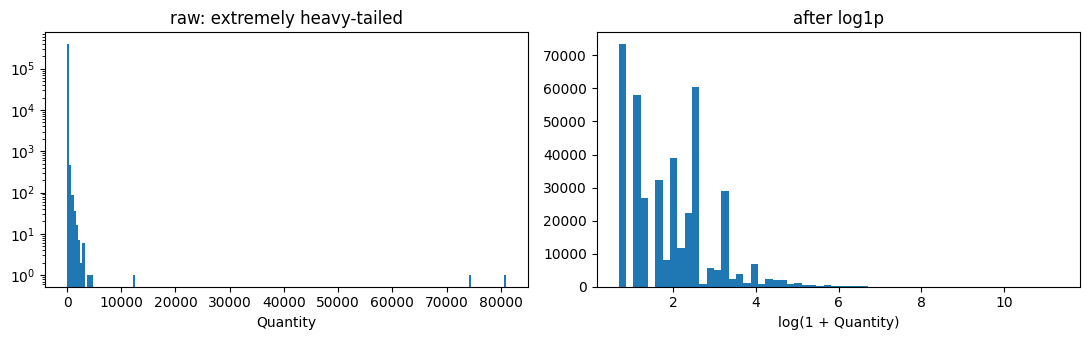

In [31]:
q = df["Quantity"].to_numpy()
print(pd.Series(q).describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(q, bins=200); axes[0].set_yscale("log"); axes[0].set(xlabel="Quantity", title="raw: extremely heavy-tailed")
axes[1].hist(np.log1p(q), bins=60); axes[1].set(xlabel="log(1 + Quantity)", title="after log1p")
plt.tight_layout(); plt.show()
t_all = np.log1p(q).astype(np.float32)

## (a) Cardinality, encoding options, and the split

> Start by exploring the cardinality of the two features. How many unique values are there for each feature? What does
> this suggest about how you might encode them? Is one-hot encoding feasible? To prepare for the next steps, split the
> data into training, validation, and test sets.

In [32]:
for c in CATS:
    counts = df[c].value_counts()
    print(f"{c:10s}: {df[c].nunique():5d} unique values | rows per value: median {counts.median():.0f}, "
          f"min {counts.min()}, max {counts.max()} | values seen only once: {(counts == 1).sum()}")
n_onehot = sum(df[c].nunique() for c in CATS)
print(f"\none-hot width = {n_onehot} columns; dense float32 matrix for {len(df)} rows = "
      f"{len(df) * n_onehot * 4 / 1e9:.1f} GB")

StockCode :  3665 unique values | rows per value: median 49, min 1, max 2035 | values seen only once: 167
CustomerID:  4339 unique values | rows per value: median 41, min 1, max 7847 | values seen only once: 72

one-hot width = 8004 columns; dense float32 matrix for 397924 rows = 12.7 GB


StockCode has 3665 unique values and CustomerID has 4339, so both are high-cardinality. One-hot encoding would create about 8000 columns, which is about 12.7 GB as a dense matrix, so it is impractical. A sparse one-hot matrix would fit, but every level would get its own independent parameter, estimated from very few rows for rare levels, and a linear model on one-hot features cannot capture customer × item interactions.

In [33]:
rng = np.random.default_rng()
perm = rng.permutation(len(df))
n_tr, n_va = int(0.70 * len(df)), int(0.15 * len(df))
idx_tr, idx_va, idx_te = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]
X_tr, X_va, X_te = df.loc[idx_tr, CATS], df.loc[idx_va, CATS], df.loc[idx_te, CATS]
t_tr, t_va, t_te = t_all[idx_tr], t_all[idx_va], t_all[idx_te]
print("train", len(t_tr), "| val", len(t_va), "| test", len(t_te))
for c in CATS:
    seen = set(X_tr[c].astype(str))
    print(f"share of test rows whose {c} is unseen in training: {np.mean(~X_te[c].astype(str).isin(seen)):.4%}")

train 278546 | val 59688 | test 59690
share of test rows whose StockCode is unseen in training: 0.0737%
share of test rows whose CustomerID is unseen in training: 0.0335%


In [34]:
def metrics(t_true, t_pred):
    return {"MSE (log1p)": float(np.mean((t_true - t_pred) ** 2)),
            "MAE (units)": float(np.mean(np.abs(np.expm1(t_pred) - np.expm1(t_true))))}

results = {}
prior = float(t_tr.mean())
results["B0 constant (train mean)"] = {**metrics(t_te, np.full(len(t_te), prior)),
                                       "val MSE": metrics(t_va, np.full(len(t_va), prior))["MSE (log1p)"]}
pd.DataFrame(results).T.round(4)

,MSE (log1p),MAE (units),val MSE
B0 constant (train mean),1.0087,11.7219,0.9965


## (b) Target encoding

> Try target encoding. For each unique value of the feature, replace it with the mean of the target for that value
> (from the training set). You can use TargetEncoder from the category encoders package. Using an appropriate loss
> function, fit a model of your choice to the data using the target-encoded features. Evaluate the model on the test set.

`TargetEncoder` is fitted on the training set only, with the modelled target $t = \log(1+Q)$. For a level seen $n$ times
with training mean $\bar t_{\text{level}}$ it returns a shrunk mean
$$\text{TE} = (1 - s_n)\,\bar t_{\text{all}} + s_n\,\bar t_{\text{level}}, \qquad s_n = \frac{1}{1 + e^{-(n - 20)/10}},$$


In [35]:
te = TargetEncoder(cols=CATS, min_samples_leaf=20, smoothing=10.0, handle_unknown="value", handle_missing="value")
te.fit(X_tr, t_tr)
TE_tr = te.transform(X_tr).to_numpy(np.float32)
TE_va = te.transform(X_va).to_numpy(np.float32)
TE_te = te.transform(X_te).to_numpy(np.float32)
print("target-encoded training features:\n", np.round(TE_tr[:5], 3))

target-encoded training features:
 [[1.262 2.173]
 [2.197 2.212]
 [1.916 1.574]
 [2.172 2.35 ]
 [1.93  2.069]]


In [36]:
lin = LinearRegression().fit(TE_tr, t_tr)
print("linear model: t_hat = %.3f + %.3f * TE(StockCode) + %.3f * TE(CustomerID)" % (lin.intercept_, *lin.coef_))
results["(b) TE + linear regression"] = {**metrics(t_te, lin.predict(TE_te)),
                                         "val MSE": metrics(t_va, lin.predict(TE_va))["MSE (log1p)"]}
pd.DataFrame(results).T.round(4)

linear model: t_hat = -1.593 + 0.874 * TE(StockCode) + 0.962 * TE(CustomerID)


,MSE (log1p),MAE (units),val MSE
B0 constant (train mean),1.0087,11.7219,0.9965
(b) TE + linear regression,0.3610,8.3927,0.3641


### A single network class for (b), (c) and (d)


In [37]:
codes = {}
for c in CATS:
    vocab = {v: i + 1 for i, v in enumerate(X_tr[c].astype(str).unique())}   # 0 = unknown
    codes[c] = vocab
def to_index(X):
    return np.stack([X[c].astype(str).map(codes[c]).fillna(0).astype(np.int64).to_numpy() for c in CATS], axis=1)
I_tr, I_va, I_te = to_index(X_tr), to_index(X_va), to_index(X_te)
n_levels = [len(codes[c]) + 1 for c in CATS]
print("embedding table sizes (incl. unknown):", dict(zip(CATS, n_levels)))


class CatNet(nn.Module):
    def __init__(self, n_levels, use_emb=True, use_te=False, emb_dim=16, hidden=64):
        super().__init__()
        self.use_emb, self.use_te = use_emb, use_te
        if use_emb:
            self.emb_stock = nn.Embedding(n_levels[0], emb_dim)
            self.emb_cust = nn.Embedding(n_levels[1], emb_dim)
        d_in = (2 * emb_dim if use_emb else 0) + (2 if use_te else 0)
        self.head = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, 1))

    def forward(self, idx, te_feats):
        parts = []
        if self.use_emb:
            parts += [self.emb_stock(idx[:, 0]), self.emb_cust(idx[:, 1])]
        if self.use_te:
            parts.append(te_feats)
        return self.head(torch.cat(parts, dim=1)).squeeze(1)


def tensors(I, TE, t):
    return torch.from_numpy(I), torch.from_numpy(TE), torch.from_numpy(t)

@torch.no_grad()
def predict(model, I, TE, batch_size=65536):
    model.eval()
    out = []
    for i in range(0, len(I), batch_size):
        idx = torch.from_numpy(I[i:i + batch_size]).to(device)
        tef = torch.from_numpy(TE[i:i + batch_size]).to(device)
        out.append(model(idx, tef).cpu())
    return torch.cat(out).numpy()

def train(model, lr=1e-3, batch_size=1024, max_epochs=30, patience=3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(*tensors(I_tr, TE_tr, t_tr)), batch_size=batch_size, shuffle=True)
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        total = 0.0
        for idx, tef, tb in loader:
            idx, tef, tb = idx.to(device), tef.to(device), tb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(idx, tef), tb)
            loss.backward()
            opt.step()
            total += loss.item() * len(tb)
        val_mse = float(np.mean((predict(model, I_va, TE_va) - t_va) ** 2))
        print(f"epoch {epoch:2d} | train MSE {total / len(t_tr):.4f} | val MSE {val_mse:.4f}")
        if val_mse < best - 1e-4:
            best, bad = val_mse, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"early stopping after epoch {epoch}; best val MSE {best:.4f}")
                break
    model.load_state_dict(best_state)
    return model

def record(name, model):
    p_te, p_va, p_tr = predict(model, I_te, TE_te), predict(model, I_va, TE_va), predict(model, I_tr, TE_tr)
    results[name] = {**metrics(t_te, p_te), "val MSE": metrics(t_va, p_va)["MSE (log1p)"],
                     "train MSE": metrics(t_tr, p_tr)["MSE (log1p)"]}
    return p_te

embedding table sizes (incl. unknown): {'StockCode': 3590, 'CustomerID': 4314}


In [38]:
torch.manual_seed(SEED)
model_te = train(CatNet(n_levels, use_emb=False, use_te=True))
pred_te_te = record("(b) TE + MLP", model_te)
pd.DataFrame(results).T.round(4)

epoch  0 | train MSE 0.6559 | val MSE 0.3669
epoch  1 | train MSE 0.3467 | val MSE 0.3561
epoch  2 | train MSE 0.3430 | val MSE 0.3561
epoch  3 | train MSE 0.3414 | val MSE 0.3534
epoch  4 | train MSE 0.3395 | val MSE 0.3521
epoch  5 | train MSE 0.3379 | val MSE 0.3506
epoch  6 | train MSE 0.3371 | val MSE 0.3524
epoch  7 | train MSE 0.3367 | val MSE 0.3504
epoch  8 | train MSE 0.3362 | val MSE 0.3543
epoch  9 | train MSE 0.3363 | val MSE 0.3488
epoch 10 | train MSE 0.3358 | val MSE 0.3492
epoch 11 | train MSE 0.3355 | val MSE 0.3483
epoch 12 | train MSE 0.3354 | val MSE 0.3490
epoch 13 | train MSE 0.3354 | val MSE 0.3488
epoch 14 | train MSE 0.3350 | val MSE 0.3500
early stopping after epoch 14; best val MSE 0.3483


,MSE (log1p),MAE (units),val MSE,train MSE
B0 constant (train mean),1.0087,11.7219,0.9965,NaN
(b) TE + linear regression,0.3610,8.3927,0.3641,NaN
(b) TE + MLP,0.3439,8.2571,0.3483,0.3348


## (c) Embedding layer for each feature

> Try a neural network model with an embedding layer for each of the two features. Choose a reasonable embedding
> dimension. Fit this model to the data. Evaluate the model on the test set. How does it compare to the target encoding
> model?

**Embedding dimension 16** for each feature. That is far smaller than the number of levels (≈ 4 000), large enough to
describe several independent "traits" of an item or customer, and it keeps the parameter count moderate:
$(3\,666 + 4\,340) \times 16 \approx 128\text{k}$ embedding weights, trained on about 279k rows.

In [39]:
model_emb = train(CatNet(n_levels, use_emb=True, use_te=False, emb_dim=16))
pred_te_emb = record("(c) embeddings + MLP", model_emb)
pd.DataFrame(results).T.round(4)

epoch  0 | train MSE 1.1595 | val MSE 0.8300
epoch  1 | train MSE 0.7377 | val MSE 0.6487
epoch  2 | train MSE 0.5710 | val MSE 0.5141
epoch  3 | train MSE 0.4564 | val MSE 0.4256
epoch  4 | train MSE 0.3869 | val MSE 0.3763
epoch  5 | train MSE 0.3471 | val MSE 0.3527
epoch  6 | train MSE 0.3238 | val MSE 0.3307
epoch  7 | train MSE 0.3077 | val MSE 0.3212
epoch  8 | train MSE 0.2985 | val MSE 0.3163
epoch  9 | train MSE 0.2919 | val MSE 0.3120
epoch 10 | train MSE 0.2869 | val MSE 0.3081
epoch 11 | train MSE 0.2826 | val MSE 0.3066
epoch 12 | train MSE 0.2794 | val MSE 0.3041
epoch 13 | train MSE 0.2770 | val MSE 0.3019
epoch 14 | train MSE 0.2745 | val MSE 0.3013
epoch 15 | train MSE 0.2721 | val MSE 0.3077
epoch 16 | train MSE 0.2706 | val MSE 0.3003
epoch 17 | train MSE 0.2683 | val MSE 0.3009
epoch 18 | train MSE 0.2664 | val MSE 0.2994
epoch 19 | train MSE 0.2649 | val MSE 0.2982
epoch 20 | train MSE 0.2628 | val MSE 0.2989
epoch 21 | train MSE 0.2613 | val MSE 0.2975
epoch 22 |

,MSE (log1p),MAE (units),val MSE,train MSE
B0 constant (train mean),1.0087,11.7219,0.9965,NaN
(b) TE + linear regression,0.3610,8.3927,0.3641,NaN
(b) TE + MLP,0.3439,8.2571,0.3483,0.3348
(c) embeddings + MLP,0.2906,7.6942,0.2955,0.2491


## (d) Target encoding **and** embeddings together

> What if we combine the two? That is, use both the target encoded features and the embeddings as input to the neural
> network. Fit this model to the data. Evaluate the model on the test set. How does it compare to the other two models?

In [40]:
torch.manual_seed(SEED)
model_both = train(CatNet(n_levels, use_emb=True, use_te=True, emb_dim=16))
pred_te_both = record("(d) embeddings + TE + MLP", model_both)
summary = pd.DataFrame(results).T[["MSE (log1p)", "MAE (units)", "val MSE", "train MSE"]]
summary.columns = ["test MSE (log1p)", "test MAE (units)", "val MSE", "train MSE"]
summary.round(4)

epoch  0 | train MSE 0.7462 | val MSE 0.3945
epoch  1 | train MSE 0.3623 | val MSE 0.3710
epoch  2 | train MSE 0.3470 | val MSE 0.3587
epoch  3 | train MSE 0.3395 | val MSE 0.3521
epoch  4 | train MSE 0.3336 | val MSE 0.3484
epoch  5 | train MSE 0.3274 | val MSE 0.3410
epoch  6 | train MSE 0.3206 | val MSE 0.3429
epoch  7 | train MSE 0.3140 | val MSE 0.3311
epoch  8 | train MSE 0.3073 | val MSE 0.3270
epoch  9 | train MSE 0.3014 | val MSE 0.3227
epoch 10 | train MSE 0.2957 | val MSE 0.3172
epoch 11 | train MSE 0.2897 | val MSE 0.3209
epoch 12 | train MSE 0.2850 | val MSE 0.3125
epoch 13 | train MSE 0.2810 | val MSE 0.3121
epoch 14 | train MSE 0.2774 | val MSE 0.3096
epoch 15 | train MSE 0.2730 | val MSE 0.3074
epoch 16 | train MSE 0.2692 | val MSE 0.3108
epoch 17 | train MSE 0.2662 | val MSE 0.3051
epoch 18 | train MSE 0.2639 | val MSE 0.3049
epoch 19 | train MSE 0.2601 | val MSE 0.3061
epoch 20 | train MSE 0.2583 | val MSE 0.3032
epoch 21 | train MSE 0.2552 | val MSE 0.3015
epoch 22 |

,test MSE (log1p),test MAE (units),val MSE,train MSE
B0 constant (train mean),1.0087,11.7219,0.9965,NaN
(b) TE + linear regression,0.3610,8.3927,0.3641,NaN
(b) TE + MLP,0.3439,8.2571,0.3483,0.3348
(c) embeddings + MLP,0.2906,7.6942,0.2955,0.2491
(d) embeddings + TE + MLP,0.2978,7.7333,0.3015,0.2502


## (e) Intuition, checked on the test set

> Try to give some intuition for your results. What is the embedding layer doing? Why might it be useful in this context?
> Evaluate your findings on the test set.

An embedding layer maps each category to a learnable 16-dimensional vector, allowing similar items or customers to develop similar representations. Unlike target encoding, embeddings learn item and customer effects jointly, capture interactions, and share information across similar categories. This helps avoid double counting and improves predictions for rare categories. Adding target encoding may not help because embeddings already capture much of its information, while training-set target encoding can introduce leakage and overfitting. Out-of-fold target encoding can help reduce this issue.

The cells below check these claims on the **test set**: 

(i) an *additive* model with jointly learned item and
customer effects separates reason 1 from reason 2; 



(ii) errors broken down by how often the item appears in training;




(iii) the train–test gap of each model.

In [41]:
# (i) Additive model with JOINTLY learned effects, no interactions:  t_hat = mu + a[item] + b[customer].
# Ridge-penalised least squares (penalty lam on a and b), solved exactly by alternating closed-form updates.
# Same integer codes as the embeddings; unseen levels (code 0) get effect 0.
lam, mu_add = 1.0, float(t_tr.mean())
a_eff, b_eff = np.zeros(n_levels[0]), np.zeros(n_levels[1])
cnt_a = np.bincount(I_tr[:, 0], minlength=n_levels[0]); cnt_b = np.bincount(I_tr[:, 1], minlength=n_levels[1])
for _ in range(30):
    a_eff = np.bincount(I_tr[:, 0], t_tr - mu_add - b_eff[I_tr[:, 1]], n_levels[0]) / (cnt_a + lam); a_eff[0] = 0
    b_eff = np.bincount(I_tr[:, 1], t_tr - mu_add - a_eff[I_tr[:, 0]], n_levels[1]) / (cnt_b + lam); b_eff[0] = 0
additive = lambda I: mu_add + a_eff[I[:, 0]] + b_eff[I[:, 1]]
results["(e) additive item + customer effects"] = {**metrics(t_te, additive(I_te)), "val MSE": metrics(t_va, additive(I_va))["MSE (log1p)"],
                                                    "train MSE": metrics(t_tr, additive(I_tr))["MSE (log1p)"]}
check = pd.DataFrame(results).T.loc[["(b) TE + MLP", "(e) additive item + customer effects", "(c) embeddings + MLP"],
                                    ["MSE (log1p)", "train MSE"]].rename(columns={"MSE (log1p)": "test MSE (log1p)"})
check.round(4)

,test MSE (log1p),train MSE
(b) TE + MLP,0.3439,0.3348
(e) additive item + customer effects,0.3058,0.2919
(c) embeddings + MLP,0.2906,0.2491


In [42]:
train_counts = X_tr["StockCode"].astype(str).value_counts()
n_seen = X_te["StockCode"].astype(str).map(train_counts).fillna(0).to_numpy()
bucket = pd.cut(n_seen, bins=[-1, 20, 100, 500, np.inf], labels=["<=20", "21-100", "101-500", ">500"])
rows = {}
for name, p in [("(b) TE + MLP", pred_te_te), ("(c) embeddings + MLP", pred_te_emb), ("(d) embeddings + TE + MLP", pred_te_both)]:
    rows[name] = pd.Series((p - t_te) ** 2).groupby(bucket, observed=True).mean()
by_freq = pd.DataFrame(rows)
by_freq.insert(0, "test rows", pd.Series(bucket).value_counts().reindex(by_freq.index).to_numpy())
print("test MSE (log1p) by how many training rows the item (StockCode) has")
by_freq.round(4)

test MSE (log1p) by how many training rows the item (StockCode) has


,test rows,(b) TE + MLP,(c) embeddings + MLP,(d) embeddings + TE + MLP
<=20,2381,0.5274,0.4163,0.4263
21-100,15216,0.3525,0.3049,0.3106
101-500,34030,0.3283,0.2766,0.2831
>500,8063,0.3396,0.2856,0.2979


In [43]:
gap = summary[["train MSE", "test MSE (log1p)"]].dropna().copy()
gap["test - train"] = gap["test MSE (log1p)"] - gap["train MSE"]
gap.round(4)

,train MSE,test MSE (log1p),test - train
(b) TE + MLP,0.3348,0.3439,0.0092
(c) embeddings + MLP,0.2491,0.2906,0.0415
(d) embeddings + TE + MLP,0.2502,0.2978,0.0477


Findings on the test set. Embeddings beat target encoding (test MSE 0.291 vs 0.344). The additive model with jointly learned item and customer effects already reaches 0.306, so most of the gain comes from fitting the effects jointly, and the remaining step to 0.291 comes from customer × item interactions. The embedding model wins in every item-frequency bucket, most clearly for rare items (≤ 20 training rows: 0.416 vs 0.527). Adding target encoding to the embeddings does not help (0.298 vs 0.291) and gives the largest train–test gap (0.048), consistent with leakage from the training-set encodings.